## Objetivo y fundamento teórico

**Bagging** entrena **un mismo algoritmo base** sobre $B$ muestras **bootstrap** (muestreo con reemplazo del
mismo tamaño $N$ que el conjunto de entrenamiento) y combina las predicciones por **votación mayoritaria**
(clasificación) o **promedio** (regresión):

$$\hat{f}_{bag}(x) = \operatorname{moda}\{\hat{f}_1(x), \dots, \hat{f}_B(x)\}$$

* Reduce la **varianza** de estimadores inestables (como árboles profundos) sin aumentar el sesgo.
* Probabilidad de que una muestra **no** sea elegida en un bootstrap: $(1 - 1/N)^N \to e^{-1} \approx 0.368$.
  Por tanto cada árbol ve ≈ **63.2 %** de muestras únicas; el **36.8 %** restante son instancias
  **Out-Of-Bag (OOB)** que permiten estimar el error de generalización "gratis".

**Se elige la versión clasificadora** (`BaggingClassifier`) sobre el dataset *breast_cancer* (diagnóstico de
tumores malignos/benignos), comparándola con un árbol CART individual.

In [1]:
# Librerías y configuración global de reproducibilidad
import os, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)
REPO_RAW = "https://raw.githubusercontent.com/Edwardmamani/ML-UNAP-Tarea-Ejecucion-03/main"


def load_csv(name):
    """Carga un CSV desde data/ (local) o desde el repositorio GitHub (Colab)."""
    local = os.path.join("data", name)
    return pd.read_csv(local if os.path.exists(local) else f"{REPO_RAW}/data/{name}")


def savefig(name):
    """Guarda la figura actual en figures/ (se reutiliza en el informe .docx)."""
    plt.savefig(f"figures/{name}.png", dpi=160, bbox_inches="tight")


def bootstrap_ci(y_true, y_score, metric, n_boot=1000, seed=RANDOM_STATE):
    """Intervalo de confianza bootstrap al 95% de una métrica sobre el conjunto de prueba."""
    rng = np.random.default_rng(seed)
    y_true, y_score = np.asarray(y_true), np.asarray(y_score)
    vals = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_true), len(y_true))
        if len(np.unique(y_true[idx])) < 2 and metric.__name__ == "roc_auc_score":
            continue
        vals.append(metric(y_true[idx], y_score[idx]))
    return np.percentile(vals, [2.5, 97.5])


def save_results(obj, name):
    """Guarda los resultados en results/<name>.json (insumo del informe)."""
    with open(f"results/{name}.json", "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, ensure_ascii=False,
                  default=lambda o: o.item() if hasattr(o, "item") else str(o))


def plot_roc(ax, model, X_eval, y_eval, name, color=None, lw=1.8):
    """Dibuja la curva ROC de un modelo (compatible con cualquier versión de scikit-learn)."""
    from sklearn.metrics import roc_curve, roc_auc_score
    score = model.predict_proba(X_eval)[:, 1]
    fpr, tpr, _ = roc_curve(y_eval, score)
    ax.plot(fpr, tpr, color=color, lw=lw, label=f"{name} (AUC = {roc_auc_score(y_eval, score):.3f})")
    ax.set_xlabel("Tasa de falsos positivos"); ax.set_ylabel("Tasa de verdaderos positivos")
    ax.legend(loc="lower right", fontsize=8)


print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

scikit-learn 1.9.1 | pandas 3.1.0 | numpy 2.4.6


## 1. Datos y partición estratificada 80/20

In [2]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold

X, y = load_breast_cancer(return_X_y=True, as_frame=True)   # 0 = maligno, 1 = benigno
print("Dimensiones:", X.shape, "| nulos:", int(X.isna().sum().sum()),
      "| clases:", y.value_counts().to_dict())
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y,
                                                    random_state=RANDOM_STATE)
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Dimensiones: (569, 30) | nulos: 0 | clases: {1: 357, 0: 212}
Train: (455, 30) | Test: (114, 30)


El dataset no tiene valores faltantes ni requiere escalamiento (los árboles son invariantes a la escala).
Se usa la misma partición estratificada que en el Ítem 1 para que los resultados sean comparables.

## 2. Modelos: árbol individual vs. Bagging

In [3]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier

dt_full = DecisionTreeClassifier(random_state=RANDOM_STATE)
dt_reg = DecisionTreeClassifier(max_depth=4, min_samples_leaf=0.16, random_state=RANDOM_STATE)  # config. del apunte

models = {
    "Árbol individual (sin podar)": dt_full,
    "Árbol individual (depth=4, leaf=16%)": dt_reg,
    "Bagging 300 árboles (sin podar)": BaggingClassifier(estimator=dt_full, n_estimators=300, oob_score=True,
                                                         n_jobs=-1, random_state=RANDOM_STATE),
    "Bagging 300 árboles (depth=4, leaf=16%)": BaggingClassifier(estimator=dt_reg, n_estimators=300,
                                                                 oob_score=True, n_jobs=-1,
                                                                 random_state=RANDOM_STATE),
}
for k, v in models.items():
    print(f"{k:42s} -> {v}")

Árbol individual (sin podar)               -> DecisionTreeClassifier(random_state=42)
Árbol individual (depth=4, leaf=16%)       -> DecisionTreeClassifier(max_depth=4, min_samples_leaf=0.16, random_state=42)
Bagging 300 árboles (sin podar)            -> BaggingClassifier(estimator=DecisionTreeClassifier(random_state=42),
                  n_estimators=300, n_jobs=-1, oob_score=True, random_state=42)
Bagging 300 árboles (depth=4, leaf=16%)    -> BaggingClassifier(estimator=DecisionTreeClassifier(max_depth=4,
                                                   min_samples_leaf=0.16,
                                                   random_state=42),
                  n_estimators=300, n_jobs=-1, oob_score=True, random_state=42)


## 3. Evaluación: entrenamiento, CV 10-Fold, OOB y prueba

In [4]:
from sklearn.model_selection import cross_validate
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             make_scorer)

scoring = {"accuracy": "accuracy", "roc_auc": "roc_auc", "f1_mal": make_scorer(f1_score, pos_label=0)}
rows, cv_acc = [], {}
for name, model in models.items():
    cvres = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    t0 = time.perf_counter(); model.fit(X_train, y_train); fit_t = time.perf_counter() - t0
    y_pred = model.predict(X_test); y_proba = model.predict_proba(X_test)[:, 1]
    cv_acc[name] = cvres["test_accuracy"]
    rows.append({
        "Modelo": name,
        "Acc. train": accuracy_score(y_train, model.predict(X_train)),
        "Acc. CV (media)": cvres["test_accuracy"].mean(),
        "Acc. CV (std)": cvres["test_accuracy"].std(),
        "Acc. OOB": getattr(model, "oob_score_", np.nan),
        "Acc. test": accuracy_score(y_test, y_pred),
        "Precisión maligno": precision_score(y_test, y_pred, pos_label=0),
        "Recall maligno": recall_score(y_test, y_pred, pos_label=0),
        "F1 maligno": f1_score(y_test, y_pred, pos_label=0),
        "ROC-AUC test": roc_auc_score(y_test, y_proba),
        "Tiempo fit (s)": fit_t,
    })
results = pd.DataFrame(rows).set_index("Modelo")
results.round(4)

,Acc. train,Acc. CV (media),Acc. CV (std),Acc. OOB,Acc. test,Precisión maligno,Recall maligno,F1 maligno,ROC-AUC test,Tiempo fit (s)
Modelo,,,,,,,,,,
Árbol individual (sin podar),1.0000,0.9253,0.0416,NaN,0.9123,0.8478,0.9286,0.8864,0.9157,0.0124
"Árbol individual (depth=4, leaf=16%)",0.9231,0.8857,0.0413,NaN,0.9211,0.9231,0.8571,0.8889,0.9658,0.0070
Bagging 300 árboles (sin podar),1.0000,0.9627,0.0367,0.9648,0.9474,0.9286,0.9286,0.9286,0.9931,1.2058
"Bagging 300 árboles (depth=4, leaf=16%)",0.9451,0.9209,0.0200,0.9209,0.9474,0.9091,0.9524,0.9302,0.9884,0.7403


_(análisis pendiente)_

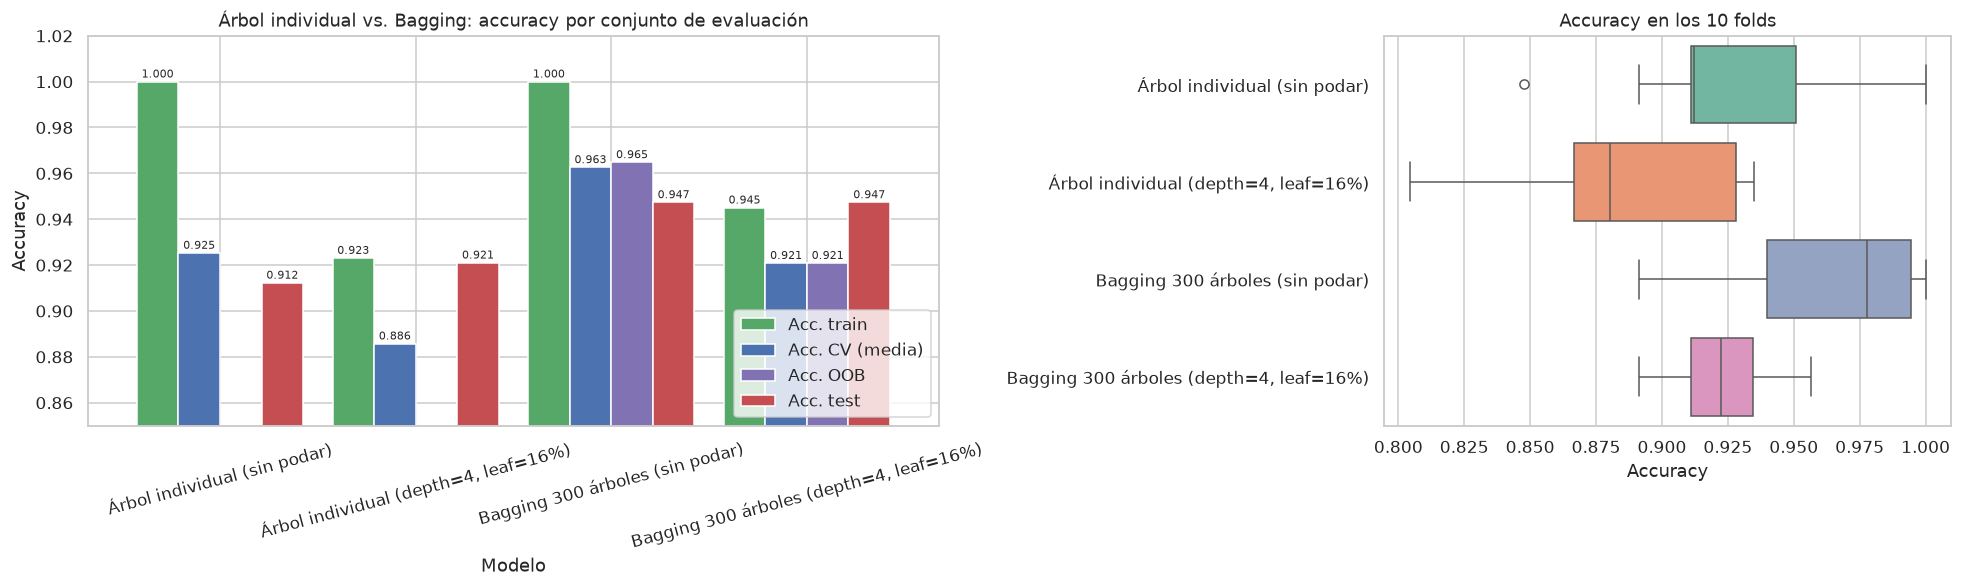

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5.5), gridspec_kw={"width_ratios": [1.5, 1]})
results[["Acc. train", "Acc. CV (media)", "Acc. OOB", "Acc. test"]].plot(
    kind="bar", ax=axes[0], color=["#55A868", "#4C72B0", "#8172B3", "#C44E52"], width=0.85)
axes[0].set_ylim(0.85, 1.02); axes[0].set_ylabel("Accuracy"); axes[0].tick_params(axis="x", rotation=15)
axes[0].set_title("Árbol individual vs. Bagging: accuracy por conjunto de evaluación")
for c in axes[0].containers:
    axes[0].bar_label(c, fmt="%.3f", fontsize=7, padding=1)
axes[0].legend(loc="lower right")
cv_df = pd.DataFrame(cv_acc).melt(var_name="Modelo", value_name="Accuracy")
sns.boxplot(data=cv_df, y="Modelo", x="Accuracy", hue="Modelo", palette="Set2", legend=False, ax=axes[1])
axes[1].set_title("Accuracy en los 10 folds"); axes[1].set_ylabel("")
plt.tight_layout(); savefig("item4_comparacion"); plt.show()

_(análisis pendiente)_

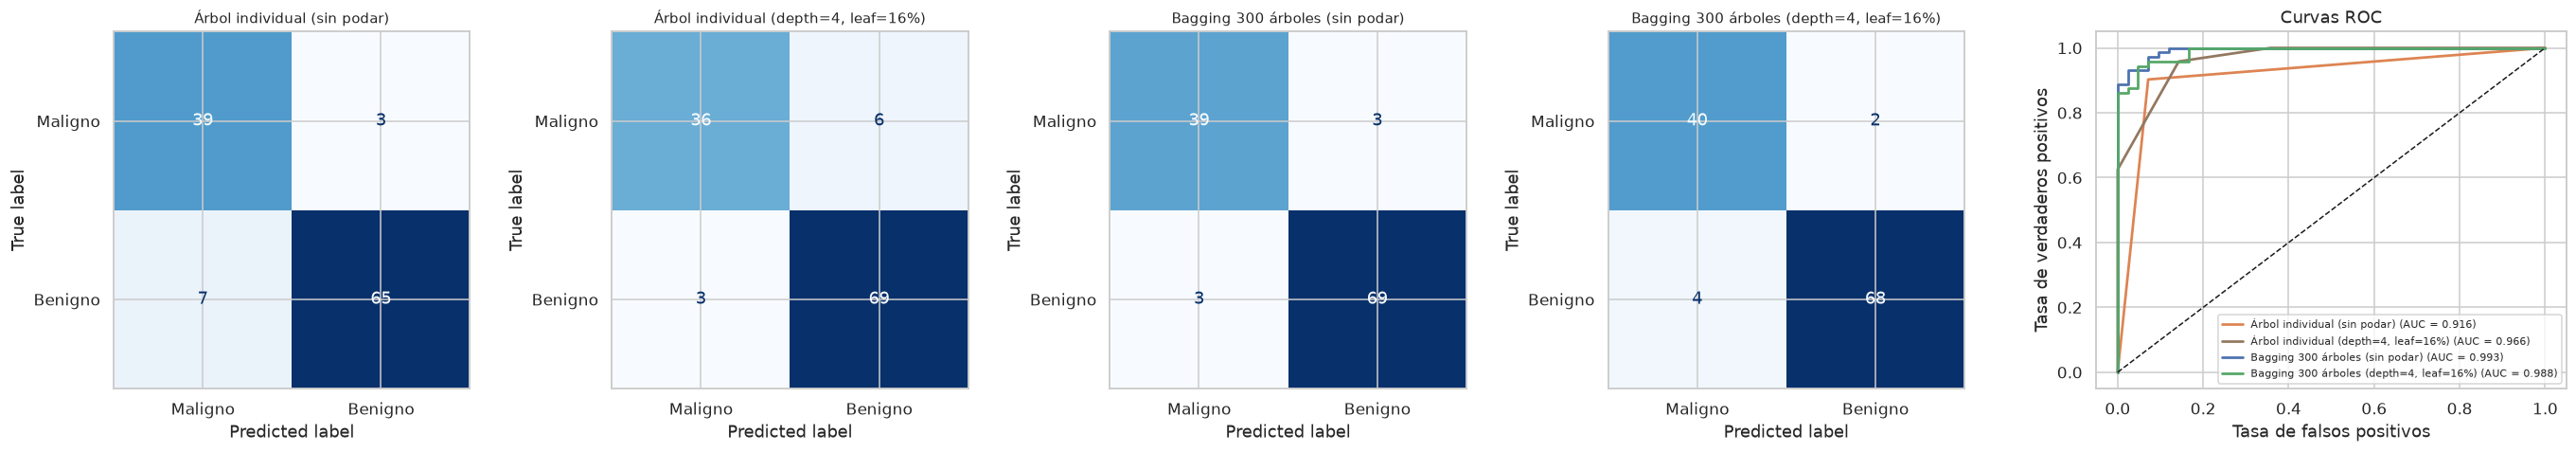

In [6]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 5, figsize=(25, 4.5), gridspec_kw={"width_ratios": [1, 1, 1, 1, 1.25]})
for ax, (name, model) in zip(axes[:4], models.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, model.predict(X_test), labels=[0, 1],
                                            display_labels=["Maligno", "Benigno"], cmap="Blues",
                                            colorbar=False, ax=ax)
    ax.set_title(name, fontsize=9.5)
for (name, model), col in zip(models.items(), ["#DD8452", "#937860", "#4C72B0", "#55A868"]):
    plot_roc(axes[4], model, X_test, y_test, name, color=col)
axes[4].plot([0, 1], [0, 1], "k--", lw=1); axes[4].set_title("Curvas ROC"); axes[4].legend(fontsize=7)
plt.tight_layout(); savefig("item4_confusion_roc"); plt.show()

_(análisis pendiente)_

## 4. Verificación empírica del muestreo bootstrap y de la estimación OOB

Fracción media de muestras únicas por bootstrap: 0.6315 (teórico 1 - e^-1 = 0.6321)
Fracción OOB media: 0.3685 (teórico e^-1 = 0.3679)


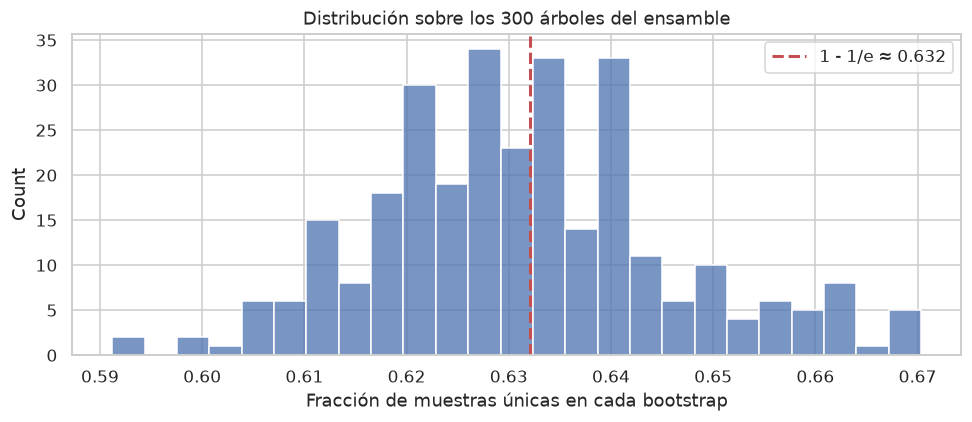

In [7]:
bc = models["Bagging 300 árboles (sin podar)"]
n = len(X_train)
frac_unique = np.array([len(np.unique(s)) / n for s in bc.estimators_samples_])
print(f"Fracción media de muestras únicas por bootstrap: {frac_unique.mean():.4f} "
      f"(teórico 1 - e^-1 = {1 - np.exp(-1):.4f})")
print(f"Fracción OOB media: {1 - frac_unique.mean():.4f} (teórico e^-1 = {np.exp(-1):.4f})")

fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(frac_unique, bins=25, color="#4C72B0", ax=ax)
ax.axvline(1 - np.exp(-1), color="#C44E52", ls="--", lw=2, label="1 - 1/e ≈ 0.632")
ax.set_xlabel("Fracción de muestras únicas en cada bootstrap"); ax.legend()
ax.set_title("Distribución sobre los 300 árboles del ensamble")
plt.tight_layout(); savefig("item4_bootstrap"); plt.show()

_(análisis pendiente)_

## 5. Convergencia del ensamble según `n_estimators`

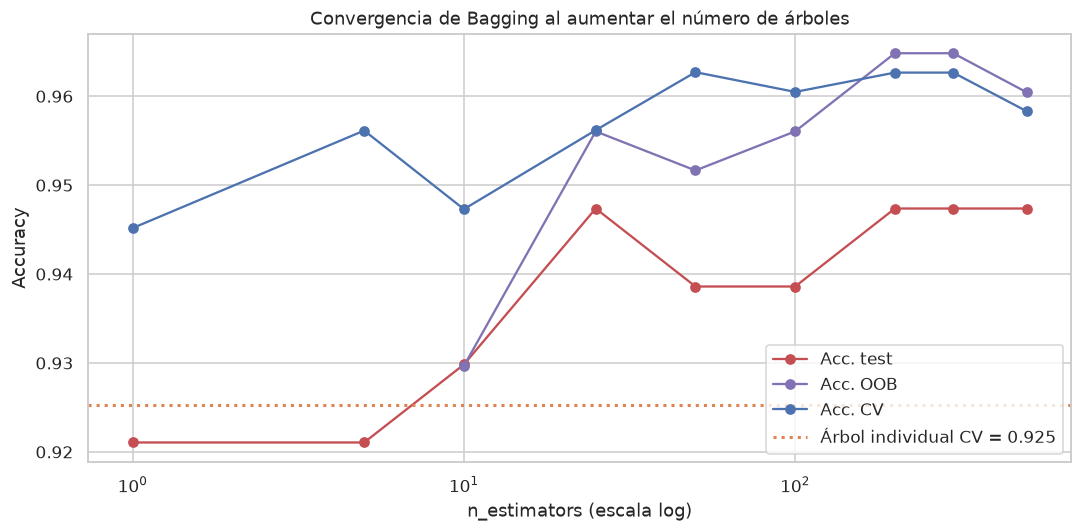

,n_estimators,Acc. test,Acc. OOB,Acc. CV
0,1,0.9211,NaN,0.9452
1,5,0.9211,NaN,0.9561
2,10,0.9298,0.9297,0.9473
3,25,0.9474,0.9560,0.9562
4,50,0.9386,0.9516,0.9627
5,100,0.9386,0.9560,0.9605
6,200,0.9474,0.9648,0.9627
7,300,0.9474,0.9648,0.9627
8,500,0.9474,0.9604,0.9583


In [8]:
n_list = [1, 5, 10, 25, 50, 100, 200, 300, 500]
conv = []
for n_est in n_list:
    m = BaggingClassifier(estimator=dt_full, n_estimators=n_est, oob_score=n_est >= 10, n_jobs=-1,
                          random_state=RANDOM_STATE).fit(X_train, y_train)
    conv.append({"n_estimators": n_est, "Acc. test": m.score(X_test, y_test),
                 "Acc. OOB": m.oob_score_ if n_est >= 10 else np.nan,
                 "Acc. CV": cross_validate(m, X_train, y_train, cv=cv, n_jobs=-1)["test_score"].mean()})
conv = pd.DataFrame(conv)
dt_cv = results.loc["Árbol individual (sin podar)", "Acc. CV (media)"]
fig, ax = plt.subplots(figsize=(10, 5))
for col, c in [("Acc. test", "#C44E52"), ("Acc. OOB", "#8172B3"), ("Acc. CV", "#4C72B0")]:
    ax.plot(conv["n_estimators"], conv[col], "-o", color=c, label=col)
ax.axhline(dt_cv, color="#DD8452", ls=":", lw=2, label=f"Árbol individual CV = {dt_cv:.3f}")
ax.set_xscale("log"); ax.set_xlabel("n_estimators (escala log)"); ax.set_ylabel("Accuracy")
ax.set_title("Convergencia de Bagging al aumentar el número de árboles"); ax.legend()
plt.tight_layout(); savefig("item4_convergencia"); plt.show()
conv.round(4)

_(análisis pendiente)_

## 6. Reducción de varianza: 30 particiones aleatorias distintas

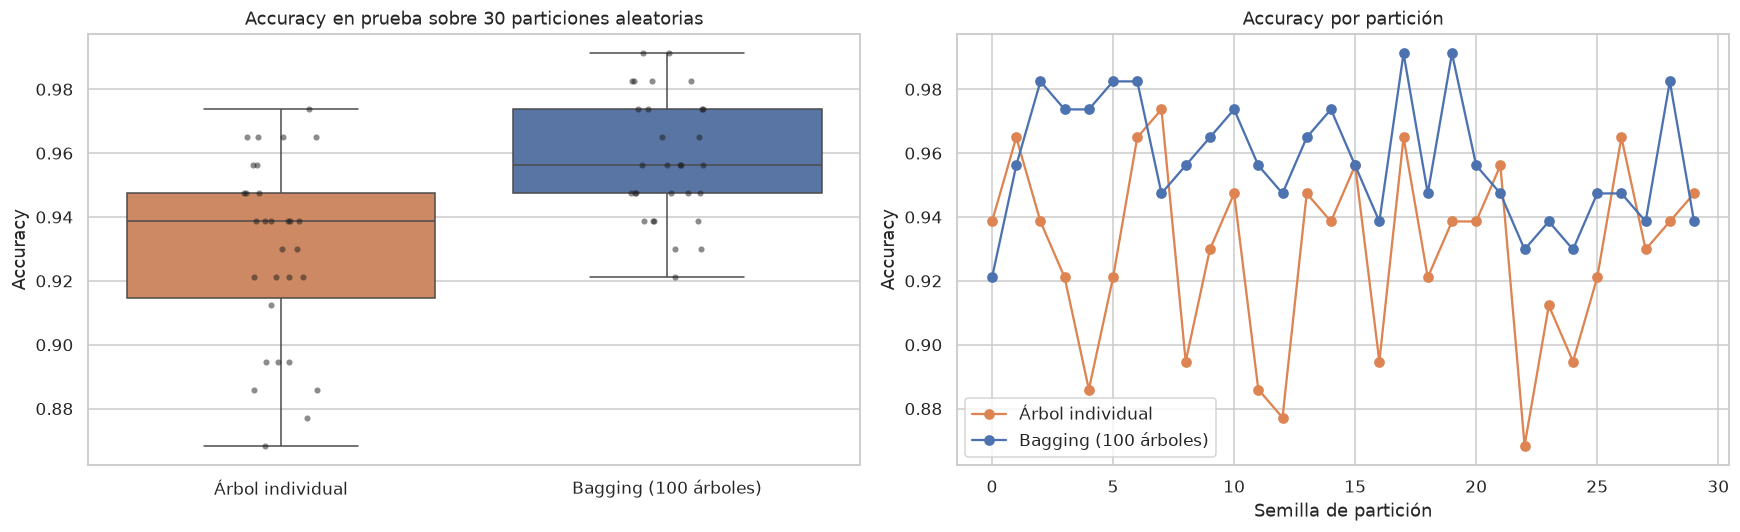

Bagging supera al árbol en 23 de 30 particiones


,mean,std,min,max
Modelo,,,,
Bagging (100 árboles),0.9579,0.0193,0.9211,0.9912
Árbol individual,0.9292,0.0289,0.8684,0.9737


In [9]:
var_rows = []
for seed in range(30):
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.2, stratify=y, random_state=seed)
    t = DecisionTreeClassifier(random_state=seed).fit(Xa, ya)
    b = BaggingClassifier(estimator=DecisionTreeClassifier(random_state=seed), n_estimators=100,
                          n_jobs=-1, random_state=seed).fit(Xa, ya)
    var_rows += [{"Modelo": "Árbol individual", "seed": seed, "Accuracy": t.score(Xb, yb)},
                 {"Modelo": "Bagging (100 árboles)", "seed": seed, "Accuracy": b.score(Xb, yb)}]
var_df = pd.DataFrame(var_rows)
summary_var = var_df.groupby("Modelo")["Accuracy"].agg(["mean", "std", "min", "max"])
wins = (var_df.pivot(index="seed", columns="Modelo", values="Accuracy")
        .pipe(lambda d: (d["Bagging (100 árboles)"] > d["Árbol individual"]).sum()))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.boxplot(data=var_df, x="Modelo", y="Accuracy", hue="Modelo", palette=["#DD8452", "#4C72B0"],
            legend=False, ax=axes[0])
sns.stripplot(data=var_df, x="Modelo", y="Accuracy", color="k", size=4, alpha=0.5, ax=axes[0])
axes[0].set_title("Accuracy en prueba sobre 30 particiones aleatorias"); axes[0].set_xlabel("")
piv = var_df.pivot(index="seed", columns="Modelo", values="Accuracy")
axes[1].plot(piv.index, piv["Árbol individual"], "-o", color="#DD8452", label="Árbol individual")
axes[1].plot(piv.index, piv["Bagging (100 árboles)"], "-o", color="#4C72B0", label="Bagging (100 árboles)")
axes[1].set_xlabel("Semilla de partición"); axes[1].set_ylabel("Accuracy"); axes[1].legend()
axes[1].set_title("Accuracy por partición")
plt.tight_layout(); savefig("item4_varianza"); plt.show()
print(f"Bagging supera al árbol en {wins} de 30 particiones")
summary_var.round(4)

_(análisis pendiente)_

## 7. Significancia estadística e IC bootstrap

In [10]:
from scipy.stats import wilcoxon
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score

rcv = RepeatedStratifiedKFold(n_splits=10, n_repeats=3, random_state=RANDOM_STATE)
rep = {n: cross_val_score(models[n], X_train, y_train, cv=rcv, scoring="accuracy", n_jobs=-1) for n in models}
pairs = [("Bagging 300 árboles (sin podar)", "Árbol individual (sin podar)"),
         ("Bagging 300 árboles (depth=4, leaf=16%)", "Árbol individual (depth=4, leaf=16%)"),
         ("Bagging 300 árboles (sin podar)", "Árbol individual (depth=4, leaf=16%)")]
stats_rows = []
for a, b in pairs:
    p = wilcoxon(rep[a], rep[b], zero_method="zsplit").pvalue
    stats_rows.append({"Comparación": f"{a} vs {b}", "Acc. A": rep[a].mean(), "Acc. B": rep[b].mean(),
                       "Diferencia A-B": (rep[a] - rep[b]).mean(), "p-valor Wilcoxon": p,
                       "Significativo (α=0.05)": "Sí" if p < 0.05 else "No"})
p_var = wilcoxon(piv["Bagging (100 árboles)"], piv["Árbol individual"], zero_method="zsplit").pvalue
stats_rows.append({"Comparación": "Bagging(100) vs Árbol — 30 particiones", 
                   "Acc. A": piv["Bagging (100 árboles)"].mean(), "Acc. B": piv["Árbol individual"].mean(),
                   "Diferencia A-B": (piv["Bagging (100 árboles)"] - piv["Árbol individual"]).mean(),
                   "p-valor Wilcoxon": p_var, "Significativo (α=0.05)": "Sí" if p_var < 0.05 else "No"})
stats_df = pd.DataFrame(stats_rows)
ci_df = pd.DataFrame({n: bootstrap_ci(y_test, models[n].predict(X_test), accuracy_score) for n in models},
                     index=["IC95% inf", "IC95% sup"]).T
display(stats_df.round(4)); display(ci_df.round(4))

,Comparación,Acc. A,Acc. B,Diferencia A-B,p-valor Wilcoxon,Significativo (α=0.05)
0,Bagging 300 árboles (sin podar) vs Árbol indiv...,0.9590,0.9188,0.0403,0.0000,Sí
1,"Bagging 300 árboles (depth=4, leaf=16%) vs Árb...",0.9187,0.8858,0.0329,0.0001,Sí
2,Bagging 300 árboles (sin podar) vs Árbol indiv...,0.9590,0.8858,0.0732,0.0000,Sí
3,Bagging(100) vs Árbol — 30 particiones,0.9579,0.9292,0.0287,0.0001,Sí


,IC95% inf,IC95% sup
Árbol individual (sin podar),0.8596,0.9561
"Árbol individual (depth=4, leaf=16%)",0.8684,0.9649
Bagging 300 árboles (sin podar),0.9035,0.9825
"Bagging 300 árboles (depth=4, leaf=16%)",0.9035,0.9825


_(análisis pendiente)_

In [11]:
save_results({
    "results": results.reset_index().to_dict(orient="records"),
    "bootstrap_unique_frac": float(frac_unique.mean()),
    "convergence": conv.to_dict(orient="records"),
    "variance_30_splits": summary_var.reset_index().to_dict(orient="records"),
    "bagging_wins_30": int(wins),
    "stats": stats_df.to_dict(orient="records"),
    "ci": ci_df.reset_index().rename(columns={"index": "Modelo"}).to_dict(orient="records"),
}, "item4")
print("Resultados guardados en results/item4.json")

Resultados guardados en results/item4.json


## Conclusiones
_(pendiente)_